In [10]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, IntSlider
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import pandas as pd
import netCDF4 as nc


In [75]:
file_path = "/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/Alaia/LTL_ns_corrected_one.nc"
ds = xr.open_dataset(file_path)
print(ds)
# 提取 Diatoms 在 time=1 的数据（ny=52, nx=25 的二维数组）
diatoms_data = ds['Diatoms'].sel(time=1)

# 转换为 Pandas DataFrame（行=ny，列=nx）
df = pd.DataFrame(diatoms_data.values,
                 index=diatoms_data.ny.values,  # 行索引为 ny 坐标
                 columns=diatoms_data.nx.values)  # 列索引为 nx 坐标

# 保存为 CSV 文件
df.to_csv("/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/Alaia/diatoms_time1.csv")
print("已成功保存为 diatoms_time1.csv")

<xarray.Dataset> Size: 2MB
Dimensions:                   (nx: 25, ny: 52, time: 24)
Coordinates:
  * nx                        (nx) float64 200B -4.0 -3.5 -3.0 ... 7.0 7.5 8.0
  * ny                        (ny) float64 416B 49.0 49.25 49.5 ... 61.5 61.75
  * time                      (time) int32 96B 1 2 3 4 5 6 ... 19 20 21 22 23 24
Data variables:
    MicroPhytoplankton        (time, ny, nx) float64 250kB ...
    Diatoms                   (time, ny, nx) float64 250kB ...
    HeterotrophicFlagellates  (time, ny, nx) float64 250kB ...
    Microzooplankton          (time, ny, nx) float64 250kB ...
    Mesozooplankton           (time, ny, nx) float64 250kB ...
    DepositFeeders            (time, ny, nx) float64 250kB ...
    SuspensionFeeders         (time, ny, nx) float64 250kB ...
    Meiobenthos               (time, ny, nx) float64 250kB ...
    LargeBenthos              (time, ny, nx) float64 250kB ...
    VeryLargeBenthos          (time, ny, nx) float64 250kB ...
Attributes:
    di

In [93]:
file_path = "/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Phy_ECS.nc"
ds = xr.open_dataset(file_path)
print(ds)

ds['O2'] = ds['O2'] / 8.5 * 100

ds.to_netcdf("/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Phy_ECS_percent.nc")


max_temp = ds['O2'].min().item()  # .item() 将结果从数组转为标量

print(f"全局最大温度值: {max_temp} °C")
# print(ds['T'].sel(time=1, nz=3).values)

# # 提取 time=1, nz=3 的温度数据（21x29 的二维数组）
# temp_data = ds['T'].sel(time=1, nz=3)

# # 转换为 Pandas DataFrame（行=ny，列=nx）
# df = pd.DataFrame(temp_data.values, 
#                   index=temp_data.ny.values,  # 行索引为 ny 坐标
#                   columns=temp_data.nx.values)  # 列索引为 nx 坐标

# # 保存为 CSV
# df.to_csv("temperature_time1_nz3.csv")
# print("已保存为 temperature_time1_nz3.csv")

<xarray.Dataset> Size: 12MB
Dimensions:  (time: 600, nz: 2, ny: 21, nx: 29)
Coordinates:
  * nz       (nz) int64 16B 1 3
  * nx       (nx) int32 116B 0 1 2 3 4 5 6 7 8 9 ... 20 21 22 23 24 25 26 27 28
  * ny       (ny) int32 84B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20
  * time     (time) int64 5kB 1 2 3 4 5 6 7 8 ... 594 595 596 597 598 599 600
Data variables:
    T        (time, nz, ny, nx) float64 6MB ...
    O2       (time, nz, ny, nx) float64 6MB ...
全局最大温度值: 73.13222518317548 °C


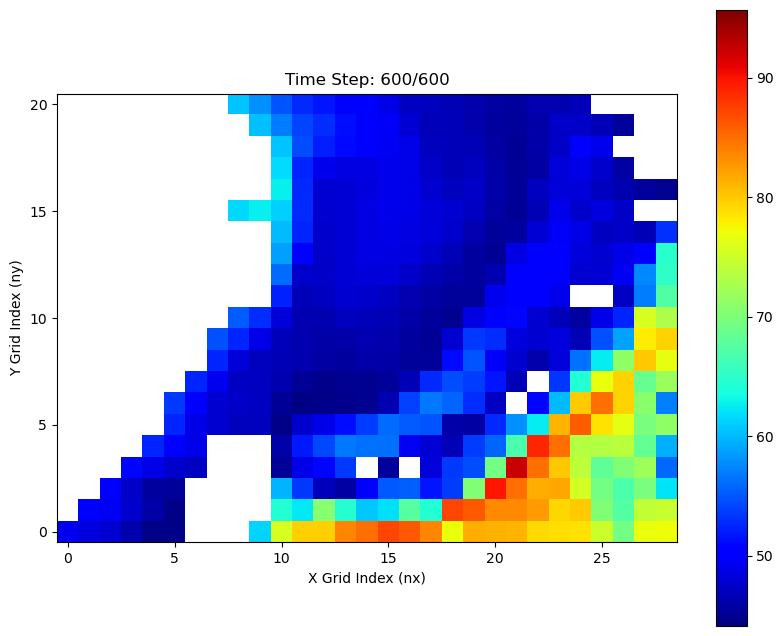

In [81]:
temp_data = ds['O2'].isel(nz=1)  # 选择第一个垂直层（nz=1）

# 设置图形
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(temp_data[0], cmap='jet', origin='lower')
plt.colorbar(im)
title = ax.set_title('Time Step: 1/600')

# 添加坐标轴标签（假设是网格索引）
ax.set_xlabel('X Grid Index (nx)')
ax.set_ylabel('Y Grid Index (ny)')
ax.set_xticks(np.arange(0, 29, 5))
ax.set_yticks(np.arange(0, 21, 5))

# 动画更新函数
def update(frame):
    im.set_array(temp_data[frame])
    title.set_text(f'Time Step: {frame+1}/600')
    return im, title

# 创建动画
ani = FuncAnimation(
    fig, 
    update, 
    frames=600,  # 600个时间步
    interval=50,  # 每帧50毫秒（速度可调）
    blit=True
)

# 保存为GIF（需要pillow）
# ani.save('temperature_animation.gif', writer='pillow', fps=15, dpi=100)

# 或者在Jupyter中直接显示
HTML(ani.to_jshtml())

# LTL

In [23]:
file_path = "/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Ltl_ECS.nc"
ds = xr.open_dataset(file_path)
print(ds)


max_temp = ds['SmallPhytoplankton'].max().item()  # .item() 将结果从数组转为标量

print(f"全局最大值: {max_temp}")


# 放大所有数据变量 100 倍
scaled_ds = ds.copy()
for var in ds.data_vars:
    scaled_ds[var] = ds[var] * 10000

max_temp = scaled_ds['SmallPhytoplankton'].max().item()  # .item() 将结果从数组转为标量

print(f"全局最大值: {max_temp}")


# 保存为新的nc文件
scaled_ds.to_netcdf("/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Ltl_ECS_bio*10000.nc")

print("新文件已保存为 1970_1990_2019_Ltl_ECS_bio*10000.nc")

<xarray.Dataset> Size: 15MB
Dimensions:               (time: 600, ny: 21, nx: 29)
Coordinates:
  * nx                    (nx) float64 232B 117.3 117.8 118.3 ... 130.5 131.0
  * ny                    (ny) float64 168B 23.17 23.65 24.13 ... 32.32 32.8
  * time                  (time) int64 5kB 1 2 3 4 5 6 ... 596 597 598 599 600
Data variables:
    SmallPhytoplankton    (time, ny, nx) float64 3MB ...
    LargePhytoplankton    (time, ny, nx) float64 3MB ...
    SmallZooplankton      (time, ny, nx) float64 3MB ...
    LargeZooplankton      (time, ny, nx) float64 3MB ...
    PredatoryZooplankton  (time, ny, nx) float64 3MB ...
全局最大值: 270915.7765534881
全局最大值: 2709157765.534881


Animation size has reached 21006013 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


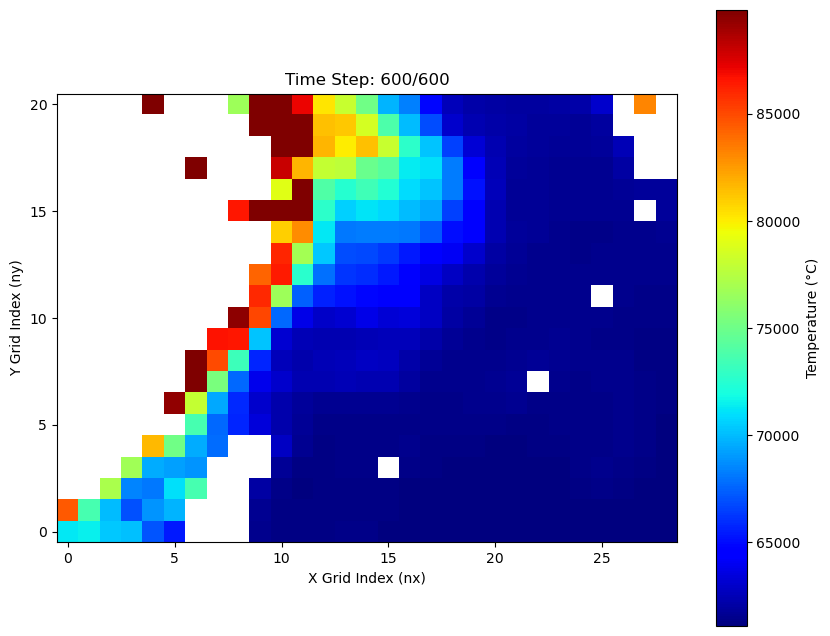

In [10]:
temp_data = ds['SmallPhytoplankton']  # 选择第一个垂直层（nz=1）

# 设置图形
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(temp_data[0], cmap='jet', origin='lower')
plt.colorbar(im, label='Temperature (°C)')
title = ax.set_title('Time Step: 1/600')

# 添加坐标轴标签（假设是网格索引）
ax.set_xlabel('X Grid Index (nx)')
ax.set_ylabel('Y Grid Index (ny)')
ax.set_xticks(np.arange(0, 29, 5))
ax.set_yticks(np.arange(0, 21, 5))

# 动画更新函数
def update(frame):
    im.set_array(temp_data[frame])
    title.set_text(f'Time Step: {frame+1}/600')
    return im, title

# 创建动画
ani = FuncAnimation(
    fig, 
    update, 
    frames=600,  # 600个时间步
    interval=50,  # 每帧50毫秒（速度可调）
    blit=True
)

# 保存为GIF（需要pillow）
# ani.save('temperature_animation.gif', writer='pillow', fps=15, dpi=100)

# 或者在Jupyter中直接显示
HTML(ani.to_jshtml())

### 提取某一年

In [114]:
import xarray as xr

# 打开 nc 文件
ds = xr.open_dataset("/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Phy_ECS_percent.nc")

# 获取 time 的长度
time_len = ds.dims['time']

# 遍历 nz = 1 和 3，对 T 和 O2 进行处理
for level in [1, 3]:
    # 提取 time=600 时刻（注意 Python 从 0 开始，所以 time=600 对应索引为599）
    t_600 = ds['T'].sel(time=599, nz=level)
    o2_600 = ds['O2'].sel(time=599, nz=level)
    
    # 扩展为 time 的维度
    t_broadcast = t_600.expand_dims(dim="time").broadcast_like(ds['T'].sel(nz=level))
    o2_broadcast = o2_600.expand_dims(dim="time").broadcast_like(ds['O2'].sel(nz=level))
    
    # 替换数据
    ds['T'].loc[dict(nz=level)] = t_broadcast
    ds['O2'].loc[dict(nz=level)] = o2_broadcast

# 保存为新文件（可选）
ds.to_netcdf("/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Phy_ECS_percent_2100.nc")


/var/folders/q1/6glgk9k16xx84r20syk5b2q80000gn/T/ipykernel_67368/1514037061.py:7: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  time_len = ds.dims['time']


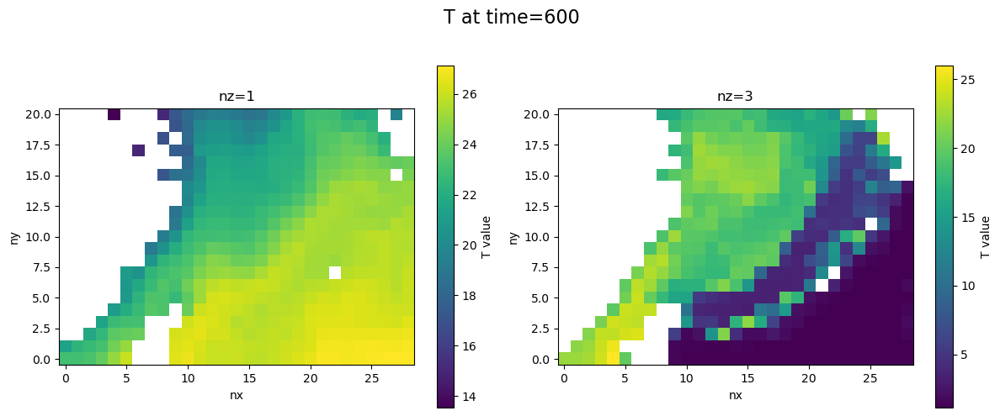

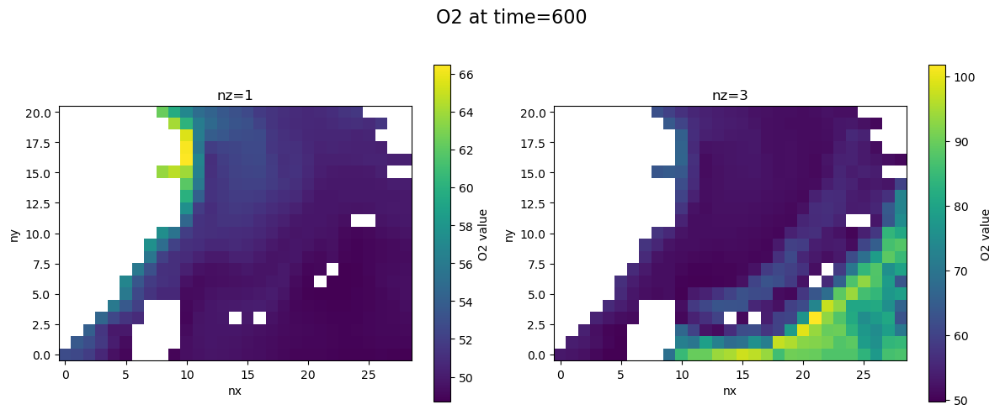

In [116]:

ds = xr.open_dataset("/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/osmose__4.3.3_calibrar_data/osmose_4.3.3_calibrar_0411/master/1970_1990_2019_Phy_ECS_percent_2100.nc")

# 可视化变量列表
vars_to_plot = ['T', 'O2']
nz_levels = [1, 3]
time_index = 599  # 对应 time=600

# 开始绘图
for var in vars_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f"{var} at time=600", fontsize=16)

    for i, nz_val in enumerate(nz_levels):
        data_2d = ds[var].sel(time=time_index, nz=nz_val)

        im = axes[i].imshow(data_2d, origin='lower', cmap='viridis')
        axes[i].set_title(f"nz={nz_val}")
        axes[i].set_xlabel('nx')
        axes[i].set_ylabel('ny')

        # 添加 colorbar
        cbar = fig.colorbar(im, ax=axes[i])
        cbar.set_label(f"{var} value")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


# Alaia-LTL

In [81]:
file_path = "/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/Alaia/physical_ns.nc"
ds = xr.open_dataset(file_path)
print(ds)


max_temp = ds['O2'].max().item()  # .item() 将结果从数组转为标量

print(f"全局最大值: {max_temp}")


<xarray.Dataset> Size: 1MB
Dimensions:  (time: 24, nz: 3, ny: 52, nx: 25)
Coordinates:
  * nx       (nx) float64 200B -4.0 -3.5 -3.0 -2.5 -2.0 ... 6.0 6.5 7.0 7.5 8.0
  * ny       (ny) float64 416B 49.0 49.25 49.5 49.75 ... 61.0 61.25 61.5 61.75
  * nz       (nz) int32 12B 1 2 3
  * time     (time) int32 96B 1 2 3 4 5 6 7 8 9 ... 16 17 18 19 20 21 22 23 24
Data variables:
    O2       (time, nz, ny, nx) float64 749kB ...
    T        (time, nz, ny, nx) float64 749kB ...
Attributes:
    dimension_ltl:  0=Temperature 1=O2
    history:        Thu Mar 11 09:54:56 2021: ncks -d nx,0,24 -d ny,0,51 phys...
    NCO:            4.7.2
全局最小值: 100.0


/var/folders/q1/6glgk9k16xx84r20syk5b2q80000gn/T/ipykernel_65274/1909058723.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


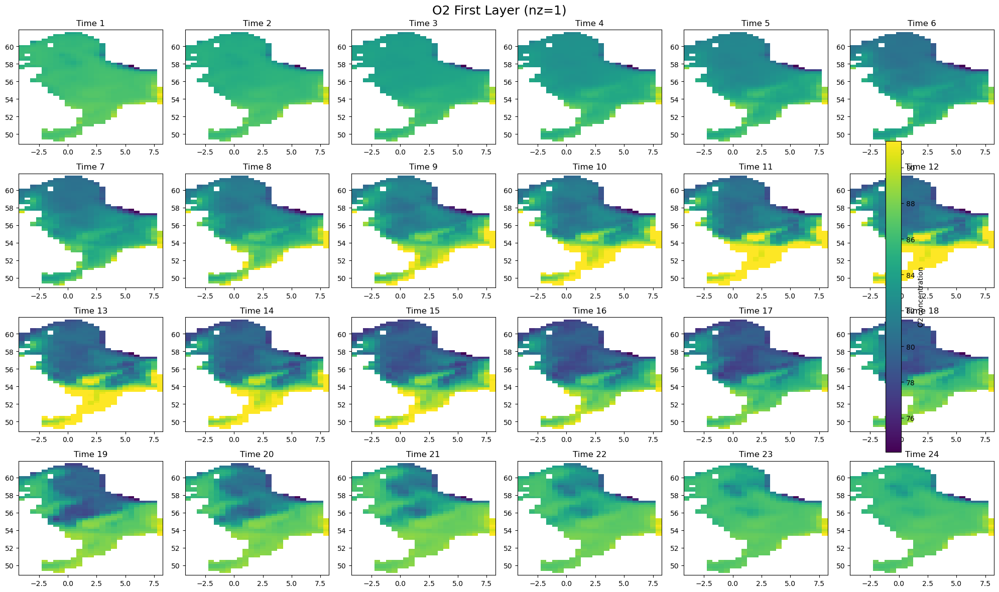

In [89]:
ds = xr.open_dataset('/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/Alaia/physical_ns.nc')

# 提取 O2 第一层 (nz=1)
O2_nz1 = ds['O2'].sel(nz=1)

# 画图：每个time一个图，4行6列布局
fig, axes = plt.subplots(4, 6, figsize=(20, 12))
axes = axes.flatten()

# 先画第一幅图，获取 colorbar 对象
p = O2_nz1.isel(time=0).plot(ax=axes[0], cmap='viridis', add_colorbar=False)

axes[0].set_title(f'Time {int(ds.time[0].values)}')
axes[0].set_xlabel('')
axes[0].set_ylabel('')

# 画剩下的
for i in range(1, 24):
    O2_nz1.isel(time=i).plot(ax=axes[i], cmap='viridis', add_colorbar=False)
    axes[i].set_title(f'Time {int(ds.time[i].values)}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

# 加统一 colorbar
cbar = fig.colorbar(p, ax=axes.tolist(), orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label('O2 concentration')

# 全局标题
plt.suptitle('O2 First Layer (nz=1)', fontsize=18)
plt.tight_layout()
plt.show()

# 环境变量处理转换，平均环境因子

In [14]:
ns_phy = nc.Dataset('/Users/dengwenbo/Desktop/Student/PHD/OSMOSE/ECS-OSMOSE/Alaia/physical_ns.nc')
ns_phy

<class 'netCDF4._netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimension_ltl: 0=Temperature 1=O2
    history: Thu Mar 11 09:54:56 2021: ncks -d nx,0,24 -d ny,0,51 physical_ns.nc physical_ns.nc
    NCO: 4.7.2
    dimensions(sizes): time(24), nz(3), ny(52), nx(25)
    variables(dimensions): float64 O2(time, nz, ny, nx), float64 T(time, nz, ny, nx), float64 nx(nx), float64 ny(ny), int32 nz(nz), int32 time(time)
    groups: 

In [29]:
ecs_phy = nc.Dataset('1970_1990_2019_Phy_ECS.nc')
ecs_phy
print(len(ecs_phy['time']))


600


In [95]:

ecs_phy_ = xr.open_dataset('1970_1990_2019_Phy_ECS_percent.nc')

# 只保留 time 从240开始（Python是0起算，所以240: 相当于删掉前240个）
ecs_phy_cut = ecs_phy_.isel(time=slice(240, 600))  # 600不含，正好240~599共360个time

# 检查一下新 time 长度
print(f"剩余 time 长度: {len(ecs_phy_cut['time'])}")  # 应该是360

# 创建30年对应的 months (12个月 × 30年 = 360)
months = np.tile(np.arange(1, 13), 30)

# 加入 months 坐标
ecs_phy_cut = ecs_phy_cut.assign_coords(month=("time", months))

# 按月平均
ecs_phy_year = ecs_phy_cut.groupby('month').mean('time')

ecs_phy_year = ecs_phy_year.rename({'month': 'time'})

# 保存
ecs_phy_year.to_netcdf('1990_2019_ecs_phy_ave.nc')

print(ecs_phy_year)


剩余 time 长度: 360
<xarray.Dataset> Size: 234kB
Dimensions:  (time: 12, nz: 2, ny: 21, nx: 29)
Coordinates:
  * nz       (nz) int64 16B 1 3
  * nx       (nx) int32 116B 0 1 2 3 4 5 6 7 8 9 ... 20 21 22 23 24 25 26 27 28
  * ny       (ny) int32 84B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20
  * time     (time) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    T        (time, nz, ny, nx) float64 117kB 17.45 17.65 18.12 ... nan nan nan
    O2       (time, nz, ny, nx) float64 117kB 90.66 90.11 89.53 ... nan nan nan


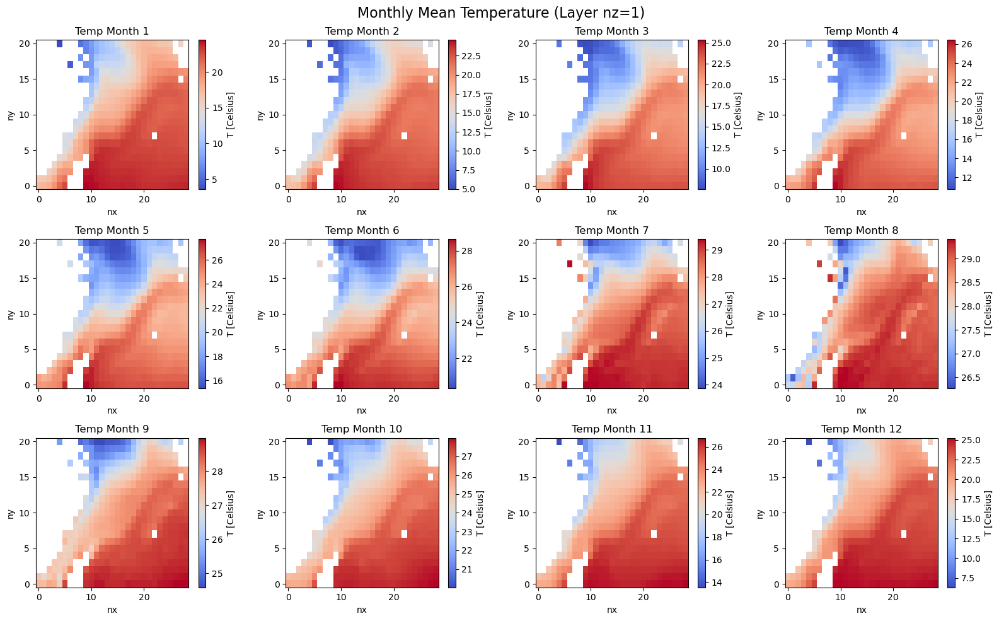

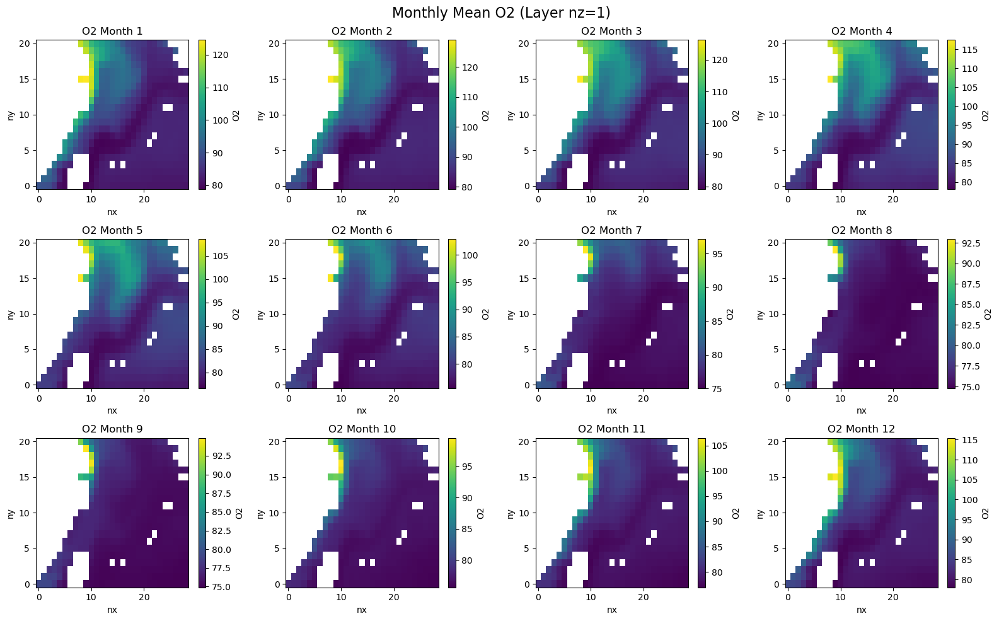

In [97]:
ds = xr.open_dataset('1990_2019_ecs_phy_ave.nc')

# 选择第一个深度层 nz=0（因为 nz 有2层：1 和 3）
# 如果你要画第2层，可以改成 sel(nz=3)
T = ds['T'].sel(nz=1)  # 第一层
O2 = ds['O2'].sel(nz=1)  # 第一层

# 画 T 的12个月
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i in range(12):
    T.isel(time=i).plot(ax=axes[i], cmap='coolwarm')
    axes[i].set_title(f'Temp Month {i+1}')
plt.suptitle('Monthly Mean Temperature (Layer nz=1)', fontsize=16)
plt.tight_layout()
plt.show()

# 画 O2 的12个月
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i in range(12):
    O2.isel(time=i).plot(ax=axes[i], cmap='viridis')
    axes[i].set_title(f'O2 Month {i+1}')
plt.suptitle('Monthly Mean O2 (Layer nz=1)', fontsize=16)
plt.tight_layout()
plt.show()


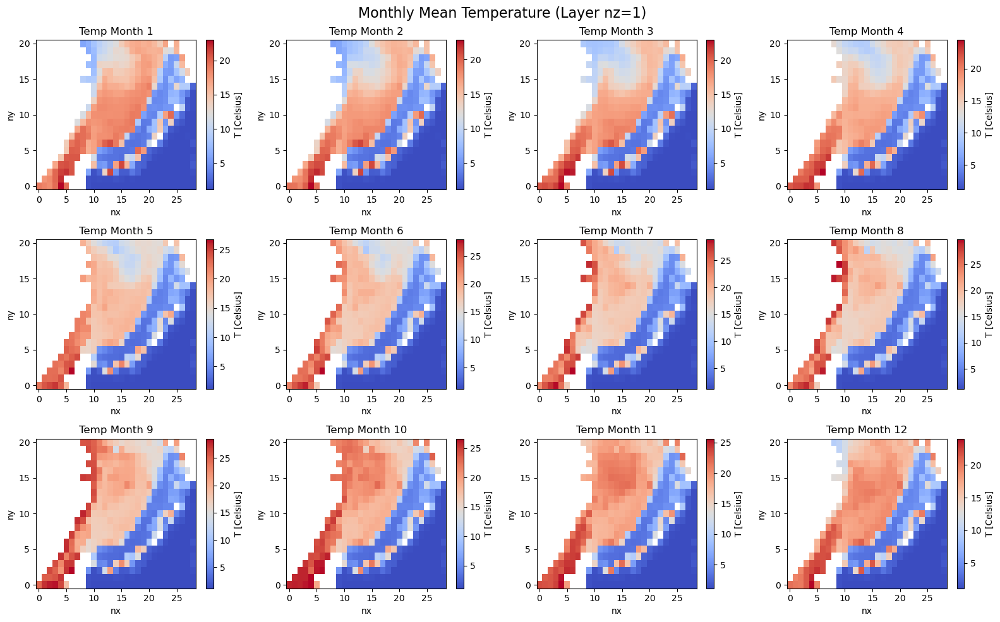

In [ ]:
ds = xr.open_dataset('1990_2019_ecs_phy_ave.nc')

# 选择第一个深度层 nz=0（因为 nz 有2层：1 和 3）
# 如果你要画第2层，可以改成 sel(nz=3)
T = ds['T'].sel(nz=3)  # 第一层
O2 = ds['O2'].sel(nz=3)  # 第一层

# 画 T 的12个月
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i in range(12):
    T.isel(time=i).plot(ax=axes[i], cmap='coolwarm')
    axes[i].set_title(f'Temp Month {i+1}')
plt.suptitle('Monthly Mean Temperature (Layer nz=1)', fontsize=16)
plt.tight_layout()
plt.show()

# 画 O2 的12个月
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i in range(12):
    O2.isel(time=i).plot(ax=axes[i], cmap='viridis')
    axes[i].set_title(f'O2 Month {i+1}')
plt.suptitle('Monthly Mean O2 (Layer nz=1)', fontsize=16)
plt.tight_layout()
plt.show()
